<a href="https://colab.research.google.com/github/LtUdon/ECG-Abnormal-Heartbeat-Detection/blob/main/Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Inventory

Before preparing the ECG data for machine learning, we need to understand how the heartbeats are distributed throughout the MIT-BIH Arrhythmia Database.

This section examines all 48 ECG recordings and counts the different heartbeat annotations provided by PhysioNet.

For our initial classification task, we focus on:
- **Normal beats (N):** Heartbeats labeled as normal.
- **PVC beats (V):** Premature ventricular contractions, which occur earlier than expected.
- **Other beat annotations:** Other types of heartbeats that are not included in our initial binary classification.

We also identify which recordings belong to the same patient. This is important because our models must be evaluated on patients they have never seen during training.

The resulting table will help us understand class imbalance and plan our training, validation, and testing datasets.

In [1]:
!pip -q install wfdb

In [2]:
import wfdb
from collections import Counter

# Load a real ECG recording from PhysioNet
record = wfdb.rdrecord("100", pn_dir="mitdb")
annotations = wfdb.rdann("100", "atr", pn_dir="mitdb")

# Count the different heartbeat types
counts = Counter(annotations.symbol)

print("Record:", record.record_name)
print("Sampling rate:", record.fs)
print("Signal channels:", record.sig_name)
print("Normal beats:", counts["N"])
print("PVC beats:", counts["V"])

Record: 100
Sampling rate: 360
Signal channels: ['MLII', 'V5']
Normal beats: 2239
PVC beats: 1


In [3]:

import wfdb
import pandas as pd
from collections import Counter

# Retrieve the official record list from PhysioNet
records = wfdb.get_record_list("mitdb")

# Store summary information for each recording
results = []

for record_id in records:

    # Read the expert heartbeat annotations
    annotations = wfdb.rdann(
        record_id,
        "atr",
        pn_dir="mitdb"
    )

    # Count every annotation symbol
    counts = Counter(annotations.symbol)

    # Only count actual heartbeat annotations as "Other"
    beat_symbols = {
        "N", "L", "R", "B", "A", "a", "J", "S",
        "V", "r", "F", "e", "j", "n", "E",
        "/", "f", "Q", "?"
    }

    normal_count = counts["N"]
    pvc_count = counts["V"]

    other_count = sum(
        count for symbol, count in counts.items()
        if symbol in beat_symbols and symbol not in {"N", "V"}
    )

    # Records 201 and 202 belong to the same patient
    patient_id = "201_202" if record_id in ["201", "202"] else record_id

    results.append({
        "Record": record_id,
        "Patient_ID": patient_id,
        "Normal": normal_count,
        "PVC": pvc_count,
        "Other_Beats": other_count,
        "Total_Beats": normal_count + pvc_count + other_count,
        "PVC_Percent": round(
            100 * pvc_count / (normal_count + pvc_count),
            2
        ) if normal_count + pvc_count > 0 else 0
    })

# Convert to a DataFrame for analysis
df = pd.DataFrame(results)

# Display the inventory
display(df)

# Display summary totals
print("Total recordings:", len(df))
print("Unique patients:", df["Patient_ID"].nunique())
print("Total normal beats:", df["Normal"].sum())
print("Total PVC beats:", df["PVC"].sum())
print("Total other beats:", df["Other_Beats"].sum())
print("Total heartbeat annotations:", df["Total_Beats"].sum())

print(
    "Records containing PVCs:",
    (df["PVC"] > 0).sum()
)


,Record,Patient_ID,Normal,PVC,Other_Beats,Total_Beats,PVC_Percent
0,100,100,2239,1,33,2273,0.04
1,101,101,1860,0,5,1865,0.00
2,102,102,99,4,2084,2187,3.88
3,103,103,2082,0,2,2084,0.00
4,104,104,163,2,2064,2229,1.21
5,105,105,2526,41,5,2572,1.60
6,106,106,1507,520,0,2027,25.65
7,107,107,0,59,2078,2137,100.00
8,108,108,1739,17,7,1763,0.97
9,109,109,0,38,2494,2532,100.00


Total recordings: 48
Unique patients: 47
Total normal beats: 75052
Total PVC beats: 7130
Total other beats: 27312
Total heartbeat annotations: 109494
Records containing PVCs: 37


## Patient-Based Data Splitting

To properly evaluate the machine learning models, we divide the dataset into training, validation, and testing groups based on individual patients rather than individual heartbeats.

This ensures that the models are tested on ECG recordings from patients they have never encountered during training.

We initially allocate approximately 60% of patients for training, 20% for validation, and 20% for testing.

We keep records 201 and 202 together because both recordings belong to the same patient.

After splitting the data, we examine the number of normal and PVC beats in each group to ensure the distribution is suitable for training and evaluation. Both the SVM and neural network will use the same patient groups.

In [4]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Use a fixed seed so everyone gets the same split
seed = 42

# First split: 60% training, 40% remaining
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.60,
    random_state=seed
)

train_idx, remaining_idx = next(
    split1.split(df, groups=df["Patient_ID"])
)

train_df = df.iloc[train_idx].copy()
remaining_df = df.iloc[remaining_idx].copy()

# Second split: divide remaining patients equally
split2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=seed
)

val_idx, test_idx = next(
    split2.split(
        remaining_df,
        groups=remaining_df["Patient_ID"]
    )
)

val_df = remaining_df.iloc[val_idx].copy()
test_df = remaining_df.iloc[test_idx].copy()

# Check that patients do not overlap
train_patients = set(train_df["Patient_ID"])
val_patients = set(val_df["Patient_ID"])
test_patients = set(test_df["Patient_ID"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

# Summarize each dataset
summary = []

for name, group in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    normal = group["Normal"].sum()
    pvc = group["PVC"].sum()

    summary.append({
        "Dataset": name,
        "Patients": group["Patient_ID"].nunique(),
        "Recordings": len(group),
        "Normal": normal,
        "PVC": pvc,
        "PVC_Percent": round(
            100 * pvc / (normal + pvc), 2
        ) if normal + pvc > 0 else 0
    })

split_summary = pd.DataFrame(summary)
display(split_summary)

print("Training records:", sorted(train_df["Record"].tolist()))
print("Validation records:", sorted(val_df["Record"].tolist()))
print("Testing records:", sorted(test_df["Record"].tolist()))

print("\nPatient overlap check: PASSED")

# Check both classes are present in every partition
assert (split_summary["Normal"] > 0).all()
assert (split_summary["PVC"] > 0).all()
print("Both-class presence check: PASSED")


,Dataset,Patients,Recordings,Normal,PVC,PVC_Percent
0,Training,28,28,46516,4790,9.34
1,Validation,9,10,13895,1475,9.60
2,Testing,10,10,14641,865,5.58


Training records: ['100', '101', '102', '105', '107', '109', '111', '112', '115', '117', '119', '122', '123', '124', '200', '208', '209', '210', '212', '213', '215', '217', '220', '221', '228', '230', '233', '234']
Validation records: ['106', '113', '116', '118', '201', '202', '203', '207', '219', '232']
Testing records: ['103', '104', '108', '114', '121', '205', '214', '222', '223', '231']

Patient overlap check: PASSED
Both-class presence check: PASSED


## Saving Patient Assignments

After dividing the ECG recordings into training, validation, and testing groups, we save the assignments in a CSV file.

This file allows everyone on the team to use exactly the same patient groups, ensuring a fair comparison between the SVM and neural network.

The assignments are based on individual patients rather than individual heartbeats to prevent patient information from appearing in multiple datasets. These groups will remain fixed throughout model development.

In [5]:

from google.colab import files
import pandas as pd

# Combine all recordings with their assigned dataset
train_export = train_df.assign(Split="Train")
val_export = val_df.assign(Split="Validation")
test_export = test_df.assign(Split="Test")

patient_splits = pd.concat(
    [train_export, val_export, test_export],
    ignore_index=True
)

# Keep the columns needed to reproduce the split
patient_splits = patient_splits[
    ["Record", "Patient_ID", "Split"]
].sort_values("Record")

# Verify all recordings are represented
assert len(patient_splits) == 48
assert patient_splits["Record"].nunique() == 48

# Save assignments
patient_splits.to_csv(
    "patient_splits.csv",
    index=False
)

display(patient_splits)

# Download the CSV to your computer
files.download("patient_splits.csv")


,Record,Patient_ID,Split
0,100,100,Train
1,101,101,Train
2,102,102,Train
38,103,103,Test
39,104,104,Test
3,105,105,Train
28,106,106,Validation
4,107,107,Train
40,108,108,Test
5,109,109,Train


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ECG Heartbeat Extraction

The MIT-BIH Arrhythmia Database contains continuous ECG recordings rather than individual heartbeat samples. Before training our machine learning models, we need to separate these recordings into individual heartbeats.

We use the heartbeat annotations provided by PhysioNet to identify the location and type of each heartbeat. For our initial experiment, we extract normal heartbeats (N) and premature ventricular contractions (V).

Each heartbeat is extracted using a fixed-length window around its annotated location. Using the same window size allows both models to receive consistently sized inputs.

We begin with Record 100 to verify that our extraction method works correctly before processing the entire database.

At this stage, we inspect the extracted waveforms without applying normalization or noise filtering. These preprocessing decisions will be evaluated separately to avoid introducing data leakage.

Record: 100
ECG lead: MLII
Sampling frequency: 360 Hz
Heartbeat window shape: (2238, 252)
Normal beats extracted: 2237
PVC beats extracted: 1


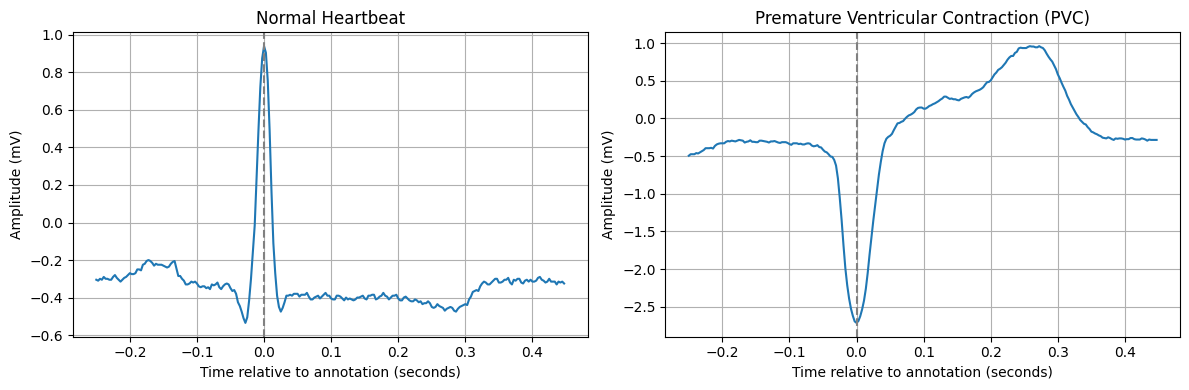

In [6]:

import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Load ECG recording and expert annotations
record_id = "100"

record = wfdb.rdrecord(record_id, pn_dir="mitdb")
annotations = wfdb.rdann(record_id, "atr", pn_dir="mitdb")

# Select the MLII ECG lead explicitly
if "MLII" not in record.sig_name:
    raise ValueError("This recording does not contain MLII")

lead_index = record.sig_name.index("MLII")
signal = record.p_signal[:, lead_index]

# Sampling frequency (360 samples per second)
fs = int(record.fs)

# Extract 0.25 seconds before and 0.45 seconds after
# the annotated heartbeat location
samples_before = int(round(0.25 * fs))
samples_after = int(round(0.45 * fs))

heartbeats = []
labels = []
beat_metadata = []

for sample, symbol in zip(
    annotations.sample,
    annotations.symbol
):
    # Only include normal beats and PVCs
    if symbol not in ("N", "V"):
        continue

    start = sample - samples_before
    end = sample + samples_after

    # Skip incomplete windows at recording boundaries
    if start < 0 or end > len(signal):
        continue

    segment = signal[start:end]

    # Skip segments with invalid numerical values
    if not np.isfinite(segment).all():
        continue

    heartbeats.append(segment)
    labels.append(0 if symbol == "N" else 1)

    beat_metadata.append({
        "Record": record_id,
        "Sample": int(sample),
        "Label": symbol
    })

# Convert to NumPy arrays
X = np.asarray(heartbeats, dtype=np.float32)
y = np.asarray(labels, dtype=np.int64)

metadata = pd.DataFrame(beat_metadata)

print("Record:", record_id)
print("ECG lead:", record.sig_name[lead_index])
print("Sampling frequency:", fs, "Hz")
print("Heartbeat window shape:", X.shape)
print("Normal beats extracted:", np.sum(y == 0))
print("PVC beats extracted:", np.sum(y == 1))

# Display one normal heartbeat and one PVC
time_axis = (
    np.arange(X.shape[1]) - samples_before
) / fs

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label_value, title in [
    (axes[0], 0, "Normal Heartbeat"),
    (axes[1], 1, "Premature Ventricular Contraction (PVC)")
]:
    matches = np.where(y == label_value)[0]

    if len(matches) > 0:
        ax.plot(time_axis, X[matches[0]])
        ax.axvline(0, linestyle="--", color="gray")
    else:
        ax.text(
            0.5, 0.5, "No examples available",
            ha="center", transform=ax.transAxes
        )

    ax.set_title(title)
    ax.set_xlabel("Time relative to annotation (seconds)")
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(True)

plt.tight_layout()
plt.show()


## ECG Lead Availability

The MIT-BIH Arrhythmia Database contains two ECG signals for each recording. However, the electrode configurations are not identical across all patients.

For this project, we prefer the Modified Lead II (MLII) signal because it is commonly available in the database and provides a consistent starting point for comparing heartbeat waveforms.

Before extracting all heartbeats, we examine the available ECG channels in each recording. This allows us to identify recordings without MLII and determine whether they require special handling.

We will document any excluded recordings and explain how these exclusions affect the final dataset.

In [7]:

import wfdb
import pandas as pd

lead_results = []

for record_id in patient_splits["Record"]:

    # Read ECG header without downloading the signal
    header = wfdb.rdheader(
        str(record_id),
        pn_dir="mitdb"
    )

    leads = header.sig_name

    lead_results.append({
        "Record": str(record_id),
        "Lead_1": leads[0],
        "Lead_2": leads[1],
        "Has_MLII": "MLII" in leads,
        "MLII_Channel": (
            leads.index("MLII")
            if "MLII" in leads else None
        )
    })

lead_df = pd.DataFrame(lead_results)

display(lead_df)

print("Total recordings:", len(lead_df))
print("Recordings with MLII:",
      lead_df["Has_MLII"].sum())
print("Recordings without MLII:",
      (~lead_df["Has_MLII"]).sum())

print("\nRecords without MLII:")
display(lead_df[~lead_df["Has_MLII"]])


,Record,Lead_1,Lead_2,Has_MLII,MLII_Channel
0,100,MLII,V5,True,0.0
1,101,MLII,V1,True,0.0
2,102,V5,V2,False,NaN
3,103,MLII,V2,True,0.0
4,104,V5,V2,False,NaN
5,105,MLII,V1,True,0.0
6,106,MLII,V1,True,0.0
7,107,MLII,V1,True,0.0
8,108,MLII,V1,True,0.0
9,109,MLII,V1,True,0.0


Total recordings: 48
Recordings with MLII: 46
Recordings without MLII: 2

Records without MLII:


,Record,Lead_1,Lead_2,Has_MLII,MLII_Channel
2,102,V5,V2,False,NaN
4,104,V5,V2,False,NaN


## Finalizing ECG Record Selection

Our ECG lead analysis found that 46 of the 48 MIT-BIH recordings contain the MLII lead. Records 102 and 104 contain different ECG leads and will be excluded from the initial experiment to keep the signal source consistent.

Record 114 contains MLII in its second channel and will remain included.

We preserve the original training, validation, and testing assignments to prevent patient overlap. The excluded recordings are documented rather than reassigned.

This step creates an updated CSV file containing only the eligible recordings. Both the SVM and neural network will use this same record selection.

In [8]:

import pandas as pd
from google.colab import files

# Use MLII availability to select eligible recordings
eligible_records = set(
    lead_df.loc[lead_df["Has_MLII"], "Record"].astype(str)
)

final_splits = patient_splits.copy()
final_splits["Record"] = final_splits["Record"].astype(str)

final_splits = final_splits[
    final_splits["Record"].isin(eligible_records)
].copy()

# Verify expected exclusions
excluded = set(patient_splits["Record"].astype(str)) - set(
    final_splits["Record"]
)

assert excluded == {"102", "104"}
assert len(final_splits) == 46

# Check the patient split is still valid
patient_groups = [
    set(final_splits.loc[
        final_splits["Split"] == split, "Patient_ID"
    ])
    for split in ["Train", "Validation", "Test"]
]

assert patient_groups[0].isdisjoint(patient_groups[1])
assert patient_groups[0].isdisjoint(patient_groups[2])
assert patient_groups[1].isdisjoint(patient_groups[2])

# Summarize the eligible recordings
print("Eligible recordings:", len(final_splits))
print("Excluded records:", sorted(excluded))
print("\nRecording counts by split:")
print(final_splits["Split"].value_counts())

# Save the updated CSV
final_splits.to_csv("eligible_patient_splits.csv", index=False)

files.download("eligible_patient_splits.csv")


Eligible recordings: 46
Excluded records: ['102', '104']

Recording counts by split:
Split
Train         27
Validation    10
Test           9
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Extracting Heartbeats from All Eligible Recordings

After identifying the 46 recordings that contain the MLII lead, we extract individual heartbeats from each recording.

We use the expert-provided annotations to locate normal heartbeats (N) and premature ventricular contractions (V). Each heartbeat is extracted using a fixed window of 252 ECG samples: 90 samples before the annotation and 162 samples after it.

The extracted heartbeats are labeled as 0 for normal and 1 for PVC. Other heartbeat types are excluded from this initial binary classification experiment.

We preserve the previously established patient-based training, validation, and testing assignments and save the extracted waveforms separately for each group.

We also record the source recording and annotation position for every heartbeat so the predictions can later be traced to their original ECG signals.

No normalization or filtering is applied at this stage. This allows us to inspect the original signal values before selecting our final preprocessing methods.

In [9]:

import wfdb
import numpy as np
import pandas as pd

# Existing patient assignments from Step 5
splits = final_splits.copy()
splits["Record"] = splits["Record"].astype(str)

# Fixed heartbeat window
SAMPLES_BEFORE = 90
SAMPLES_AFTER = 162
WINDOW_SIZE = 252

# Storage for all three datasets
datasets = {
    "Train": {"X": [], "y": [], "metadata": []},
    "Validation": {"X": [], "y": [], "metadata": []},
    "Test": {"X": [], "y": [], "metadata": []}
}

for _, row in splits.iterrows():

    record_id = row["Record"]
    split = row["Split"]

    # Load the actual ECG signal and annotations
    record = wfdb.rdrecord(record_id, pn_dir="mitdb")
    annotations = wfdb.rdann(
        record_id, "atr", pn_dir="mitdb"
    )

    # Select MLII regardless of channel position
    lead_index = record.sig_name.index("MLII")
    signal = record.p_signal[:, lead_index]

    # Check sampling frequency
    assert int(record.fs) == 360

    extracted = 0

    for sample, symbol in zip(
        annotations.sample,
        annotations.symbol
    ):

        # Binary classification: Normal vs PVC
        if symbol not in ("N", "V"):
            continue

        start = int(sample) - SAMPLES_BEFORE
        end = int(sample) + SAMPLES_AFTER

        # Exclude windows outside recording boundaries
        if start < 0 or end > len(signal):
            continue

        waveform = signal[start:end]

        # Exclude invalid values
        if not np.isfinite(waveform).all():
            continue

        # Assign class label
        label = 0 if symbol == "N" else 1

        datasets[split]["X"].append(
            waveform.astype(np.float32)
        )

        datasets[split]["y"].append(label)

        datasets[split]["metadata"].append({
            "Record": record_id,
            "Patient_ID": row["Patient_ID"],
            "Annotation_Sample": int(sample),
            "Label": label
        })

        extracted += 1

    print(
        f"Record {record_id}: "
        f"{extracted} heartbeats extracted"
    )

# Convert and save each dataset
for split in ["Train", "Validation", "Test"]:

    X = np.asarray(
        datasets[split]["X"], dtype=np.float32
    ).reshape(-1, WINDOW_SIZE)

    y = np.asarray(
        datasets[split]["y"], dtype=np.int64
    )

    metadata = pd.DataFrame(
        datasets[split]["metadata"]
    )

    filename = split.lower()

    np.savez_compressed(
        f"{filename}_ecg.npz",
        X=X,
        y=y
    )

    metadata.to_csv(
        f"{filename}_metadata.csv",
        index=False
    )

    print(f"\n{split} dataset")
    print("Waveform shape:", X.shape)
    print("Normal beats:", np.sum(y == 0))
    print("PVC beats:", np.sum(y == 1))
    print("Saved:", f"{filename}_ecg.npz")
    print("Saved:", f"{filename}_metadata.csv")


Record 100: 2238 heartbeats extracted
Record 101: 1859 heartbeats extracted
Record 103: 2081 heartbeats extracted
Record 105: 2567 heartbeats extracted
Record 106: 2027 heartbeats extracted
Record 107: 59 heartbeats extracted
Record 108: 1755 heartbeats extracted
Record 109: 38 heartbeats extracted
Record 111: 1 heartbeats extracted
Record 112: 2536 heartbeats extracted
Record 113: 1788 heartbeats extracted
Record 114: 1863 heartbeats extracted
Record 115: 1952 heartbeats extracted
Record 116: 2410 heartbeats extracted
Record 117: 1533 heartbeats extracted
Record 118: 16 heartbeats extracted
Record 119: 1987 heartbeats extracted
Record 121: 1861 heartbeats extracted
Record 122: 2475 heartbeats extracted
Record 123: 1517 heartbeats extracted
Record 124: 47 heartbeats extracted
Record 200: 2568 heartbeats extracted
Record 201: 1823 heartbeats extracted
Record 202: 2079 heartbeats extracted
Record 203: 2973 heartbeats extracted
Record 205: 2641 heartbeats extracted
Record 207: 105 heartbe

## Saving Extracted ECG Datasets

After extracting the ECG heartbeats, we save the processed datasets to Google Drive so they remain accessible after the Colab session ends.

The files include the waveform samples and class labels for training, validation, and testing, along with metadata identifying each heartbeat's original recording and annotation location.

We also preserve the patient assignment file to ensure that both machine learning models use the same data partitions. This makes our experiments reproducible and allows team members to work independently.

In [11]:

from google.colab import drive
from pathlib import Path
import shutil
import numpy as np

# Connect to Google Drive
drive.mount("/content/drive")

# Create the project data folder
destination = Path(
    "/content/drive/MyDrive/ECG-Project/data"
)
destination.mkdir(parents=True, exist_ok=True)

# Files generated by previous notebook cells
filenames = [
    "train_ecg.npz",
    "validation_ecg.npz",
    "test_ecg.npz",
    "train_metadata.csv",
    "validation_metadata.csv",
    "test_metadata.csv",
    "eligible_patient_splits.csv"
]

# Verify every expected file exists
missing = [
    name for name in filenames
    if not Path(name).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Missing files: {missing}"
    )

# Copy each file to Google Drive
for name in filenames:
    source = Path(name)
    target = destination / name

    shutil.copy2(source, target)

    if source.stat().st_size != target.stat().st_size:
        raise IOError(f"Copy verification failed: {name}")

    print(f"Saved: {name}")

# Verify that the saved data can be read
for name in [
    "train_ecg.npz",
    "validation_ecg.npz",
    "test_ecg.npz"
]:
    with np.load(destination / name) as data:
        print(
            name,
            "X:", data["X"].shape,
            "y:", data["y"].shape
        )

print("\nAll files backed up successfully.")


Mounted at /content/drive
Saved: train_ecg.npz
Saved: validation_ecg.npz
Saved: test_ecg.npz
Saved: train_metadata.csv
Saved: validation_metadata.csv
Saved: test_metadata.csv
Saved: eligible_patient_splits.csv
train_ecg.npz X: (51182, 252) y: (51182,)
validation_ecg.npz X: (15367, 252) y: (15367,)
test_ecg.npz X: (15334, 252) y: (15334,)

All files backed up successfully.


## ECG Signal Exploration and Feature Engineering

Before selecting predictors for our machine learning models, we examine the characteristics of the extracted ECG waveforms.

This analysis uses only the training dataset to avoid making feature-selection decisions based on the validation or test patients.

We examine signal amplitude, peak-to-peak range, and signal energy to understand whether normal heartbeats and premature ventricular contractions (PVCs) show measurable differences.

These are exploratory measurements rather than final predictors. We will use the results to guide feature engineering and preprocessing for the SVM and neural network.

Training data shape: (51182, 252)
Normal beats: 46397
PVC beats: 4785

Missing values:
Maximum_Amplitude    0
Minimum_Amplitude    0
Peak_to_Peak         0
Signal_Energy        0
Label                0
dtype: int64

Average measurements by heartbeat type:


,Maximum_Amplitude,Minimum_Amplitude,Peak_to_Peak,Signal_Energy
Label,,,,
0,1.175,-0.898,2.073,75.475998
1,1.318,-1.494,2.813,143.621994


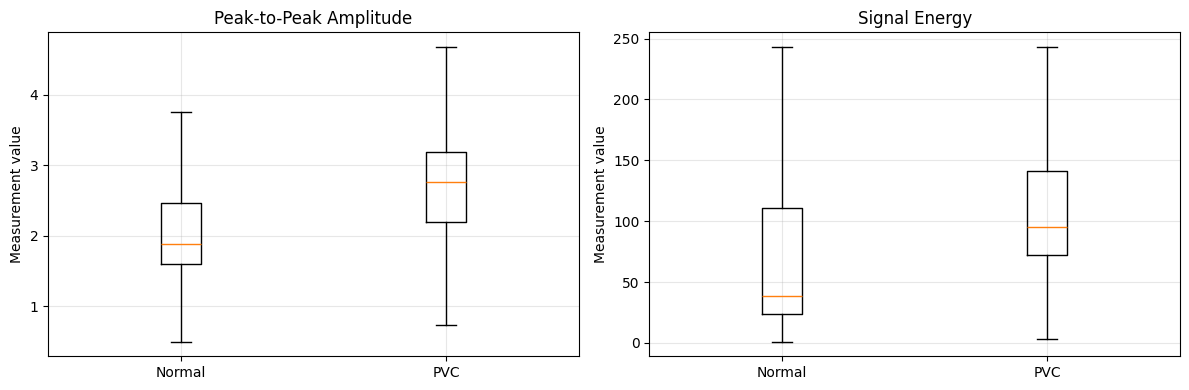

In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Location of your saved ECG data
data_folder = Path(
    "/content/drive/MyDrive/ECG-Project/data"
)

# Load training waveforms and labels
with np.load(data_folder / "train_ecg.npz") as data:
    X_train = data["X"]
    y_train = data["y"]

print("Training data shape:", X_train.shape)
print("Normal beats:", np.sum(y_train == 0))
print("PVC beats:", np.sum(y_train == 1))

# Extract basic waveform characteristics
features = pd.DataFrame({
    "Maximum_Amplitude": np.max(X_train, axis=1),
    "Minimum_Amplitude": np.min(X_train, axis=1),
    "Peak_to_Peak": np.ptp(X_train, axis=1),
    "Signal_Energy": np.sum(X_train ** 2, axis=1),
    "Label": y_train
})

# Check for invalid values
print("\nMissing values:")
print(features.isna().sum())

print("\nAverage measurements by heartbeat type:")
display(features.groupby("Label").mean().round(3))

# Compare normal heartbeats and PVCs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column, title in [
    (axes[0], "Peak_to_Peak", "Peak-to-Peak Amplitude"),
    (axes[1], "Signal_Energy", "Signal Energy")
]:
    normal = features.loc[
        features["Label"] == 0, column
    ]

    pvc = features.loc[
        features["Label"] == 1, column
    ]

    ax.boxplot(
        [normal, pvc],
        tick_labels=["Normal", "PVC"],
        showfliers=False
    )

    ax.set_title(title)
    ax.set_ylabel("Measurement value")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Feature Distribution Analysis

Our initial analysis showed that PVC heartbeats have higher average peak-to-peak amplitude and signal energy than normal heartbeats in the training dataset.

However, average values alone do not tell us how well a feature distinguishes individual heartbeats.

To investigate this, we compare the median and interquartile range (IQR) for both heartbeat types. We also visualize their distributions to see how much the values overlap.

This analysis uses only training data. The results will help us decide which measurements to include in the SVM model.

Feature statistics by heartbeat type:


Peak_to_Peak                     Signal_Energy                     \
            median    std    min   max        median         std    min   
Label                                                                     
0            1.885  0.694  0.205  5.74     38.648998   76.150002  1.150   
1            2.765  0.839  0.435  4.79     95.442001  130.895004  2.947   

                    
               max  
Label               
0      1874.098999  
1      2084.816895


Peak_to_Peak
Normal: Median=1.885, IQR=0.865
PVC: Median=2.765, IQR=0.995

Signal_Energy
Normal: Median=38.649, IQR=87.863
PVC: Median=95.442, IQR=68.373


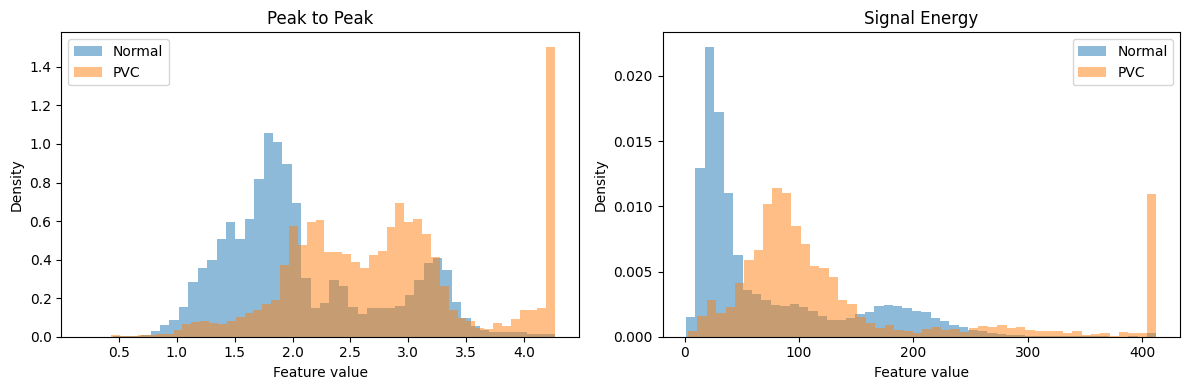

In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Features to investigate
selected_features = [
    "Peak_to_Peak",
    "Signal_Energy"
]

# Calculate summary statistics for each heartbeat type
summary = features.groupby("Label")[
    selected_features
].agg(["median", "std", "min", "max"])

print("Feature statistics by heartbeat type:")
display(summary.round(3))

# Calculate interquartile ranges
for feature in selected_features:

    print(f"\n{feature}")

    for label, name in [(0, "Normal"), (1, "PVC")]:
        values = features.loc[
            features["Label"] == label, feature
        ]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        print(
            f"{name}: Median={values.median():.3f}, "
            f"IQR={q3 - q1:.3f}"
        )

# Plot distributions without extreme outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature in zip(axes, selected_features):

    normal = features.loc[
        features["Label"] == 0, feature
    ]

    pvc = features.loc[
        features["Label"] == 1, feature
    ]

    # Use a display limit based on training data only
    upper_limit = features[feature].quantile(0.99)

    ax.hist(
        normal.clip(upper=upper_limit),
        bins=50,
        density=True,
        alpha=0.5,
        label="Normal"
    )

    ax.hist(
        pvc.clip(upper=upper_limit),
        bins=50,
        density=True,
        alpha=0.5,
        label="PVC"
    )

    ax.set_title(feature.replace("_", " "))
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


## Corrected Feature Distribution Visualization

The earlier histograms clipped extreme feature values to a common maximum, which created artificial spikes at the right edges of the graphs.

This version excludes values outside the displayed range from the visualization without changing the underlying dataset.

We compare normal and PVC heartbeat distributions using training data only. The goal is to understand how much the feature measurements overlap before selecting predictors for the SVM.

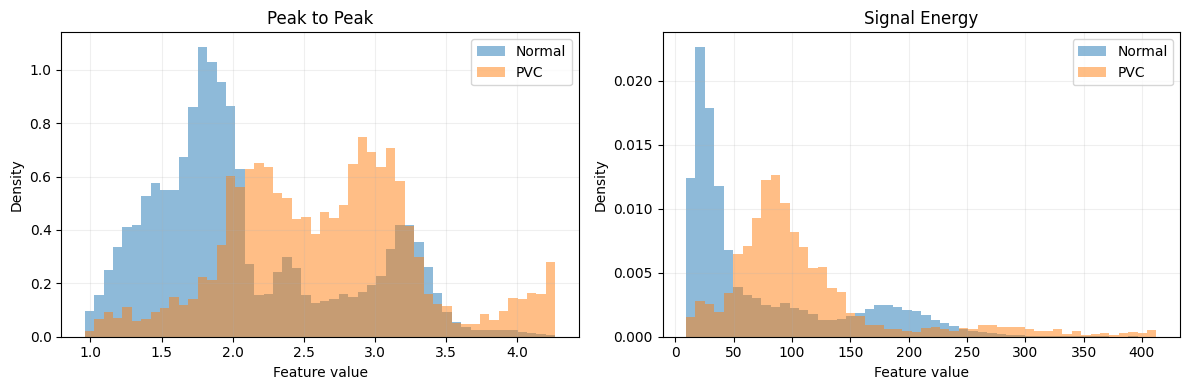

In [14]:

import numpy as np
import matplotlib.pyplot as plt

selected_features = [
    "Peak_to_Peak",
    "Signal_Energy"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature in zip(axes, selected_features):

    normal = features.loc[
        features["Label"] == 0, feature
    ]

    pvc = features.loc[
        features["Label"] == 1, feature
    ]

    # Determine display range using training data
    upper_limit = features[feature].quantile(0.99)
    lower_limit = features[feature].quantile(0.01)

    # Exclude out-of-range values from the chart only
    normal_visible = normal[
        normal.between(lower_limit, upper_limit)
    ]

    pvc_visible = pvc[
        pvc.between(lower_limit, upper_limit)
    ]

    bins = np.linspace(lower_limit, upper_limit, 51)

    ax.hist(
        normal_visible,
        bins=bins,
        density=True,
        alpha=0.5,
        label="Normal"
    )

    ax.hist(
        pvc_visible,
        bins=bins,
        density=True,
        alpha=0.5,
        label="PVC"
    )

    ax.set_title(feature.replace("_", " "))
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


## Additional ECG Waveform Features

Our previous analysis found differences in peak-to-peak amplitude and signal energy between normal heartbeats and PVCs. However, the measurements also showed considerable overlap.

To capture additional information about heartbeat shape, we calculate four more features: standard deviation, mean absolute amplitude, maximum slope, and waveform length.

These measurements describe how much the ECG signal changes and how sharply it changes over time.

We use only the training dataset for this exploratory analysis. We will later evaluate which features are most useful for the SVM without using the test patients to select predictors.

In [15]:

import numpy as np
import pandas as pd

# Calculate differences between consecutive ECG samples
signal_diff = np.diff(X_train, axis=1)

# Calculate additional waveform features
features["Standard_Deviation"] = np.std(
    X_train, axis=1
)

features["Mean_Absolute_Amplitude"] = np.mean(
    np.abs(X_train), axis=1
)

# Maximum absolute change per second (mV/s)
features["Maximum_Slope"] = np.max(
    np.abs(signal_diff), axis=1
) * 360

# Sum of absolute differences between samples
features["Waveform_Length"] = np.sum(
    np.abs(signal_diff), axis=1
)

# Display all calculated features
print("Total training heartbeats:", len(features))
print("Feature columns:")
print(features.columns.tolist())

# Compare feature medians by heartbeat type
print("\nMedian feature values by heartbeat type:")
display(
    features.groupby("Label")
    .median()
    .round(3)
)

# Verify no missing values
assert not features.isna().any().any()

print("\nAll features calculated successfully.")


Total training heartbeats: 51182
Feature columns:
['Maximum_Amplitude', 'Minimum_Amplitude', 'Peak_to_Peak', 'Signal_Energy', 'Label', 'Standard_Deviation', 'Mean_Absolute_Amplitude', 'Maximum_Slope', 'Waveform_Length']

Median feature values by heartbeat type:


,Maximum_Amplitude,Minimum_Amplitude,Peak_to_Peak,Signal_Energy,Standard_Deviation,Mean_Absolute_Amplitude,Maximum_Slope,Waveform_Length
Label,,,,,,,,
0,1.215,-0.855,1.885,38.648998,0.275,0.333,127.800003,6.55
1,1.265,-1.390,2.765,95.442001,0.571,0.482,117.000000,7.52



All features calculated successfully.


## Feature Correlation Analysis

We calculated eight waveform features from the training ECG recordings. Some of these measurements may describe similar properties of the signal.

We use a correlation matrix to examine relationships between the predictors. A correlation close to 1 indicates that two features tend to increase together, while a correlation close to -1 indicates that one tends to decrease as the other increases.

This analysis helps us identify potentially redundant features before finalizing the SVM inputs. We use training data only, keeping the validation and test patients separate from feature development.

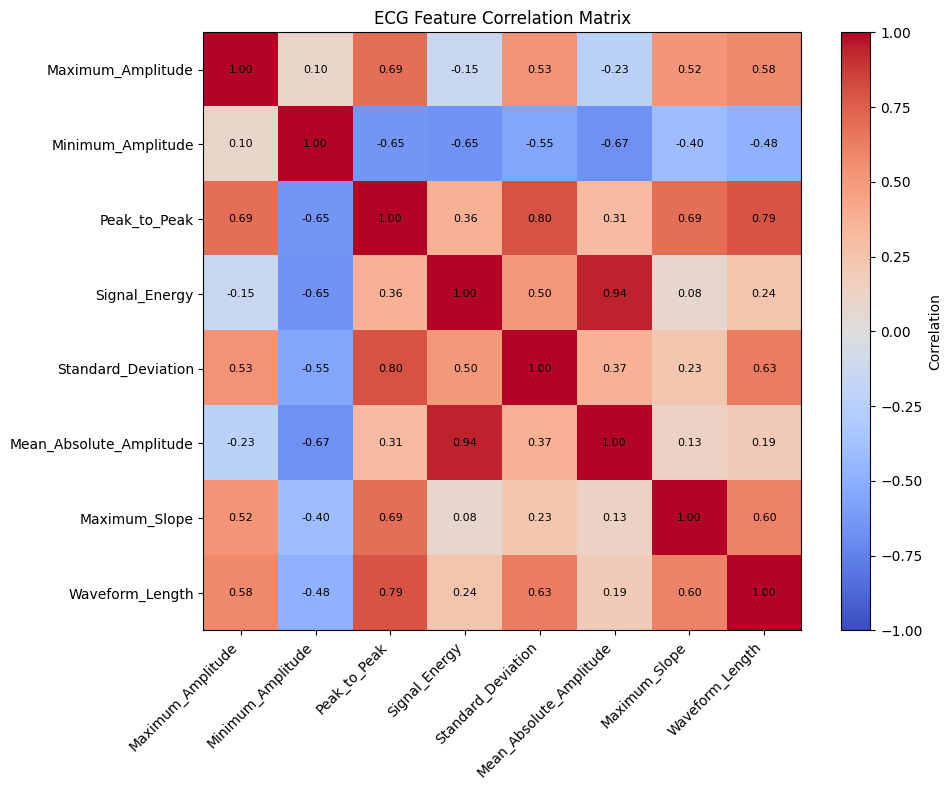

Strongly correlated feature pairs:


,Feature_1,Feature_2,Correlation
0,Signal_Energy,Mean_Absolute_Amplitude,0.945


In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Exclude the target label from predictor correlations
feature_data = features.drop(columns=["Label"])

# Calculate Pearson correlation coefficients
correlation = feature_data.corr()

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))

ax.set_xticklabels(
    correlation.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation.columns)

# Display values in each cell
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i, j]

        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(im, ax=ax, label="Correlation")
plt.title("ECG Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# Identify strongly correlated feature pairs
pairs = []

for i in range(len(correlation.columns)):
    for j in range(i + 1, len(correlation.columns)):

        value = correlation.iloc[i, j]

        if abs(value) >= 0.85:
            pairs.append({
                "Feature_1": correlation.columns[i],
                "Feature_2": correlation.columns[j],
                "Correlation": round(value, 3)
            })

print("Strongly correlated feature pairs:")
if pairs:
    display(pd.DataFrame(pairs))
else:
    print("No feature pairs above the 0.85 threshold.")
